# Ejercicio 4: análisis exploratorio con DuckDB

Aquí planteamos nuestras propias preguntas sobre los datos de 2026, con la justificación de por qué las hicimos, y las respondemos con consultas directas sobre los Parquet. Cada consulta está en `sql/ejercicio_04/` y el notebook solo la lee y la ejecuta. Las interpretaciones completas y los tres hallazgos principales están en `docs/ejercicio_04.md`.

Trabajamos sobre los viajes que pasan las reglas de limpieza que definimos en el ejercicio 3 (la vista `viajes_limpios`), salvo en la pregunta de pagos, donde necesitamos justamente los viajes que esas reglas descartan.

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 45)

SQL = Path("/workspace/sql")
con = duckdb.connect()  # en memoria, no se guarda ninguna tabla
# Los percentiles exactos sobre 28 millones de filas necesitan memoria, y el
# contenedor comparte unos 5 GB con Metabase, asi que limitamos hilos y memoria.
con.execute("SET threads = 4")
con.execute("SET memory_limit = '2GB'")
# Este analisis es de 2026, que eran los unicos datos cuando lo hicimos.
con.execute("SET VARIABLE anios = [2026]")
for archivo in ["ejercicio_03/00_vista_viajes.sql", "ejercicio_04/00_vistas_apoyo.sql"]:
    con.execute((SQL / archivo).read_text(encoding="utf-8"))

def correr(carpeta, nombre):
    """Muestra el SQL del archivo y devuelve su resultado."""
    texto = (SQL / carpeta / f"{nombre}.sql").read_text(encoding="utf-8")
    print(texto)
    return con.sql(texto).df()

## P1. ¿Cómo evoluciona el volumen de viajes por mes en cada tipo de taxi?

Empezamos por lo más básico porque todo lo demás depende de saber si el volumen es estable o tiene una tendencia. Como febrero tiene menos días que los otros meses, comparamos viajes por día y no solo el total.

In [2]:
correr('ejercicio_04', '4_1_viajes_por_mes')

-- P1. Como evoluciona el volumen de viajes por mes y tipo de taxi?
-- Los meses tienen distinta cantidad de dias, asi que ademas del total se
-- calcula el promedio de viajes por dia, que es lo comparable entre meses.
-- Fuente: vista viajes_limpios (Parquet de 2026).
SELECT
    tipo,
    strftime(pickup, '%Y-%m') AS mes,
    count(*) AS viajes,
    count(DISTINCT CAST(pickup AS DATE)) AS dias,
    round(count(*) * 1.0 / count(DISTINCT CAST(pickup AS DATE))) AS viajes_por_dia
FROM viajes_limpios
GROUP BY ALL
ORDER BY tipo, mes;



,tipo,mes,viajes,dias,viajes_por_dia
0,green,2026-01,38275,31,1235.0
1,green,2026-02,35351,28,1263.0
2,green,2026-03,42037,31,1356.0
3,green,2026-04,41908,30,1397.0
4,green,2026-05,42571,31,1373.0
5,green,2026-06,41954,30,1398.0
6,green,2026-07,38886,31,1254.0
7,green,2026-08,38275,31,1235.0
8,yellow,2026-01,3505885,31,113093.0
9,yellow,2026-02,3201188,28,114328.0


## P2. ¿A qué horas se concentra la demanda y cambia entre semana y fin de semana?

Una flota de taxis se organiza por horas, así que la curva horaria es lo que más información operativa da, y nos interesaba ver si amarillos y verdes tienen el mismo ritmo.

In [3]:
correr('ejercicio_04', '4_2_demanda_por_hora')

-- P2. A que horas se concentra la demanda y cambia entre semana y fin de semana?
-- pct es el porcentaje de los viajes de ese tipo y tipo de dia que ocurre en
-- esa hora, para poder comparar curvas de volumen muy distinto.
-- Fuente: vista viajes_limpios (Parquet de 2026).
WITH por_hora AS (
    SELECT
        tipo,
        CASE WHEN dia_semana >= 6 THEN 'fin de semana' ELSE 'entre semana' END AS tipo_dia,
        hora,
        count(*) AS viajes
    FROM viajes_limpios
    GROUP BY 1, 2, 3
)
SELECT
    tipo, tipo_dia, hora, viajes,
    round(100.0 * viajes / sum(viajes) OVER (PARTITION BY tipo, tipo_dia), 2) AS pct
FROM por_hora
ORDER BY tipo, tipo_dia, hora;



,tipo,tipo_dia,hora,viajes,pct
0,green,entre semana,0,2485,1.01
1,green,entre semana,1,1273,0.52
2,green,entre semana,2,724,0.30
3,green,entre semana,3,499,0.20
4,green,entre semana,4,797,0.33
...,...,...,...,...,...
91,yellow,fin de semana,19,475321,5.78
92,yellow,fin de semana,20,420657,5.12
93,yellow,fin de semana,21,415202,5.05
94,yellow,fin de semana,22,425768,5.18


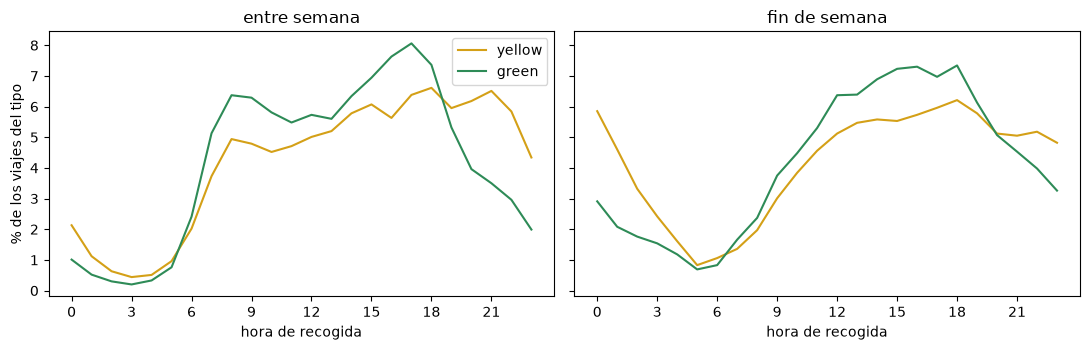

In [4]:
horas = con.sql((SQL / "ejercicio_04" / "4_2_demanda_por_hora.sql").read_text(encoding="utf-8")).df()
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for eje, tipo_dia in zip(ejes, ["entre semana", "fin de semana"]):
    for tipo, color in [("yellow", "#d4a017"), ("green", "#2e8b57")]:
        d = horas[(horas.tipo == tipo) & (horas.tipo_dia == tipo_dia)]
        eje.plot(d.hora, d.pct, label=tipo, color=color)
    eje.set_title(tipo_dia)
    eje.set_xlabel("hora de recogida")
    eje.set_xticks(range(0, 24, 3))
ejes[0].set_ylabel("% de los viajes del tipo")
ejes[0].legend()
plt.tight_layout()
plt.show()

## P2 (resumen). Las tres horas con más viajes

Resumen de la curva anterior para tener las horas pico a la vista.

In [5]:
correr('ejercicio_04', '4_2b_horas_pico')

-- P2 (resumen). Las tres horas con mas viajes por tipo de taxi y tipo de dia.
-- Fuente: vista viajes_limpios (Parquet de 2026).
WITH por_hora AS (
    SELECT
        tipo,
        CASE WHEN dia_semana >= 6 THEN 'fin de semana' ELSE 'entre semana' END AS tipo_dia,
        hora,
        count(*) AS viajes
    FROM viajes_limpios
    GROUP BY ALL
)
SELECT
    tipo, tipo_dia, hora, viajes,
    round(100.0 * viajes / sum(viajes) OVER (PARTITION BY tipo, tipo_dia), 2) AS pct,
    row_number() OVER (PARTITION BY tipo, tipo_dia ORDER BY viajes DESC) AS posicion
FROM por_hora
QUALIFY posicion <= 3
ORDER BY tipo, tipo_dia, posicion;



,tipo,tipo_dia,hora,viajes,pct,posicion
0,green,entre semana,17,19737,8.06,1
1,green,entre semana,16,18703,7.63,2
2,green,entre semana,18,18039,7.36,3
3,green,fin de semana,18,5446,7.34,1
4,green,fin de semana,16,5419,7.30,2
5,green,fin de semana,15,5371,7.23,3
6,yellow,entre semana,18,1317330,6.61,1
7,yellow,entre semana,21,1297649,6.51,2
8,yellow,entre semana,17,1271849,6.38,3
9,yellow,fin de semana,18,510507,6.21,1


## P3. ¿Qué día de la semana tiene más viajes?

Es la otra mitad del comportamiento temporal. Usamos el promedio por fecha porque en ocho meses algunos días de la semana aparecen una vez más que otros.

In [6]:
correr('ejercicio_04', '4_3_dia_de_semana')

-- P3. Que dia de la semana tiene mas viajes?
-- Se usa el promedio de viajes por fecha, porque en 8 meses algunos dias de la
-- semana ocurren una vez mas que otros.
-- Fuente: vista viajes_limpios (Parquet de 2026).
SELECT
    tipo,
    dia_semana,
    CASE dia_semana WHEN 1 THEN 'lunes' WHEN 2 THEN 'martes' WHEN 3 THEN 'miercoles'
         WHEN 4 THEN 'jueves' WHEN 5 THEN 'viernes' WHEN 6 THEN 'sabado'
         ELSE 'domingo' END AS dia,
    count(*) AS viajes,
    count(DISTINCT CAST(pickup AS DATE)) AS fechas,
    round(count(*) * 1.0 / count(DISTINCT CAST(pickup AS DATE))) AS viajes_por_fecha
FROM viajes_limpios
GROUP BY ALL
ORDER BY tipo, dia_semana;



,tipo,dia_semana,dia,viajes,fechas,viajes_por_fecha
0,green,1,lunes,45641,35,1304.0
1,green,2,martes,48392,34,1423.0
2,green,3,miercoles,50213,34,1477.0
3,green,4,jueves,52871,35,1511.0
4,green,5,viernes,47894,35,1368.0
5,green,6,sabado,38153,35,1090.0
6,green,7,domingo,36093,35,1031.0
7,yellow,1,lunes,3344626,35,95561.0
8,yellow,2,martes,3836631,34,112842.0
9,yellow,3,miercoles,4089087,34,120267.0


## P4. ¿Cómo se distribuyen la distancia, la duración y la velocidad?

En la exploración inicial vimos distancias de más de 300 mil millas, así que queríamos saber si el promedio sirve para describir un viaje típico o si hay que usar la mediana.

In [7]:
correr('ejercicio_04', '4_4_distribucion_distancia_duracion')

-- P4. Como se distribuyen la distancia, la duracion y la velocidad de los viajes?
-- Se reportan promedio y percentiles para ver si la media representa bien al
-- viaje tipico o la arrastra la cola larga. Los percentiles se piden como una
-- lista en una sola llamada, porque una llamada por percentil guarda una copia
-- de los 28 millones de valores y agota la memoria del contenedor.
-- Fuente: vista viajes_limpios (Parquet de 2026).
WITH medidas AS (
    SELECT tipo, 'distancia_millas' AS variable, trip_distance AS valor FROM viajes_limpios
    UNION ALL
    SELECT tipo, 'duracion_min', duracion_min FROM viajes_limpios
    UNION ALL
    SELECT tipo, 'velocidad_mph', velocidad_mph FROM viajes_limpios
),
resumen AS (
    SELECT
        tipo, variable,
        avg(valor) AS promedio,
        quantile_cont(valor, [0.10, 0.25, 0.50, 0.75, 0.90, 0.99]) AS p,
        max(valor) AS maximo
    FROM medidas
    GROUP BY tipo, variable
)
SELECT
    tipo, variable,
    round(promedio, 2) AS prom

,tipo,variable,promedio,p10,p25,mediana,p75,p90,p99,maximo
0,green,distancia_millas,3.38,0.89,1.34,2.16,3.79,7.55,17.76,94.10
1,green,duracion_min,17.42,5.88,8.82,13.42,20.72,32.78,75.15,359.33
2,green,velocidad_mph,11.37,6.29,7.96,10.04,13.06,18.14,31.15,1904.52
3,yellow,distancia_millas,3.53,0.70,1.10,1.94,3.97,8.70,19.57,100.00
4,yellow,duracion_min,17.74,5.45,8.67,14.15,22.28,33.50,71.35,360.00
5,yellow,velocidad_mph,10.88,4.99,6.84,9.28,12.92,18.99,34.12,2852.57


## P5. ¿Cuántas personas viajan normalmente en un taxi?

El número de pasajeros es una de las columnas con más nulos, así que lo medimos solo sobre los viajes que sí tienen el dato.

In [8]:
correr('ejercicio_04', '4_5_pasajeros')

-- P5. Cuantas personas viajan normalmente en un taxi?
-- Se excluyen los viajes sin dato de pasajeros (nulos), que en la exploracion
-- inicial resultaron ser el 26% de los amarillos y el 14% de los verdes.
-- pct es sobre los viajes que si tienen el dato.
-- Fuente: vista viajes_limpios (Parquet de 2026).
WITH por_pasajeros AS (
    SELECT tipo, passenger_count AS pasajeros, count(*) AS viajes
    FROM viajes_limpios
    WHERE passenger_count IS NOT NULL
    GROUP BY 1, 2
)
SELECT
    tipo, pasajeros, viajes,
    round(100.0 * viajes / sum(viajes) OVER (PARTITION BY tipo), 2) AS pct
FROM por_pasajeros
ORDER BY tipo, pasajeros;



,tipo,pasajeros,viajes,pct
0,green,0,4118,1.51
1,green,1,225442,82.88
2,green,2,27035,9.94
3,green,3,3008,1.11
4,green,4,2085,0.77
5,green,5,6061,2.23
6,green,6,4201,1.54
7,green,7,20,0.01
8,green,8,22,0.01
9,green,9,20,0.01


## P6. ¿Desde qué zonas salen más viajes?

Los verdes solo pueden recoger pasajeros fuera del centro de Manhattan, así que esperábamos que sus zonas fueran muy distintas a las de los amarillos.

In [9]:
correr('ejercicio_04', '4_6a_zonas_origen_top')

-- P6. Desde que zonas salen mas viajes, y es distinto entre amarillos y verdes?
-- Las 10 zonas de recogida con mas viajes por tipo, con su porcentaje del tipo.
-- Fuente: vista viajes_limpios y vista zonas (CSV de zonas de la TLC).
SELECT
    v.tipo,
    row_number() OVER (PARTITION BY v.tipo ORDER BY count(*) DESC) AS posicion,
    z.barrio,
    z.zona,
    count(*) AS viajes,
    round(100.0 * count(*) / sum(count(*)) OVER (PARTITION BY v.tipo), 2) AS pct_del_tipo
FROM viajes_limpios v
LEFT JOIN zonas z ON v.PULocationID = z.LocationID
GROUP BY v.tipo, z.barrio, z.zona
QUALIFY posicion <= 10
ORDER BY v.tipo, posicion;



,tipo,posicion,barrio,zona,viajes,pct_del_tipo
0,green,1,Manhattan,East Harlem North,86810,27.19
1,green,2,Manhattan,East Harlem South,41708,13.06
2,green,3,Queens,Forest Hills,15572,4.88
3,green,4,Manhattan,Central Park,12970,4.06
4,green,5,Manhattan,Morningside Heights,12431,3.89
5,green,6,Queens,Elmhurst,10999,3.45
6,green,7,Manhattan,Central Harlem,10953,3.43
7,green,8,Brooklyn,Downtown Brooklyn/MetroTech,10476,3.28
8,green,9,Queens,Jamaica,8949,2.80
9,green,10,Brooklyn,Fort Greene,8677,2.72


## P6 (barrios). ¿En qué barrios se recogen los viajes?

La misma pregunta a nivel de barrio, para ver si la diferencia entre amarillos y verdes se mantiene.

In [10]:
correr('ejercicio_04', '4_6b_barrio_origen')

-- P6 (barrios). En que barrios se recogen los viajes de cada tipo de taxi?
-- Fuente: vista viajes_limpios y vista zonas (CSV de zonas de la TLC).
WITH por_barrio AS (
    SELECT
        v.tipo,
        coalesce(z.barrio, '(sin zona)') AS barrio,
        count(*) AS viajes
    FROM viajes_limpios v
    LEFT JOIN zonas z ON v.PULocationID = z.LocationID
    GROUP BY 1, 2
)
SELECT
    tipo, barrio, viajes,
    round(100.0 * viajes / sum(viajes) OVER (PARTITION BY tipo), 2) AS pct_del_tipo
FROM por_barrio
ORDER BY tipo, viajes DESC;



,tipo,barrio,viajes,pct_del_tipo
0,green,Manhattan,191094,59.86
1,green,Queens,69640,21.81
2,green,Brooklyn,50180,15.72
3,green,Bronx,7842,2.46
4,green,Unknown,286,0.09
5,green,N/A,165,0.05
6,green,Staten Island,50,0.02
7,yellow,Manhattan,24414378,86.74
8,yellow,Queens,2463348,8.75
9,yellow,Brooklyn,1014086,3.60


## P7. ¿Cuáles son los pares de origen y destino más frecuentes?

Complementa las zonas de origen con el destino, para saber si los viajes más comunes son largos o locales.

In [11]:
correr('ejercicio_04', '4_12_rutas_frecuentes')

-- P12. Cuales son los pares origen y destino mas frecuentes?
-- Las 5 rutas con mas viajes por tipo, con el nombre de la zona de origen y de
-- destino. Un origen igual al destino es un viaje dentro de la misma zona.
-- Fuente: vista viajes_limpios y vista zonas (CSV de zonas de la TLC).
SELECT
    v.tipo,
    row_number() OVER (PARTITION BY v.tipo ORDER BY count(*) DESC) AS posicion,
    zo.zona AS origen,
    zd.zona AS destino,
    count(*) AS viajes,
    round(quantile_cont(v.trip_distance, 0.5), 2) AS mediana_millas,
    round(quantile_cont(v.total_amount, 0.5), 2) AS mediana_total
FROM viajes_limpios v
LEFT JOIN zonas zo ON v.PULocationID = zo.LocationID
LEFT JOIN zonas zd ON v.DOLocationID = zd.LocationID
GROUP BY v.tipo, zo.zona, zd.zona
QUALIFY posicion <= 5
ORDER BY v.tipo, posicion;



,tipo,posicion,origen,destino,viajes,mediana_millas,mediana_total
0,green,1,East Harlem North,East Harlem South,13915,1.38,13.80
1,green,2,East Harlem North,Upper East Side North,10231,1.97,21.15
2,green,3,East Harlem South,East Harlem North,7199,1.32,13.30
3,green,4,East Harlem North,Morningside Heights,6088,1.78,17.16
4,green,5,East Harlem North,Yorkville West,5109,2.25,22.33
5,yellow,1,Upper East Side South,Upper East Side North,180487,1.00,15.48
6,yellow,2,Upper East Side North,Upper East Side South,152843,1.00,15.96
7,yellow,3,Upper East Side South,Upper East Side South,119386,0.60,13.50
8,yellow,4,Upper East Side North,Upper East Side North,111801,0.56,12.60
9,yellow,5,Midtown Center,Upper East Side South,83644,1.01,18.20


## P8. ¿En qué se parecen y en qué se diferencian los viajes amarillos y verdes?

Es la comparación central que pide el ejercicio, con medianas de distancia, duración y montos, y el comportamiento de las propinas en pagos con tarjeta, porque en efectivo no se registran.

In [12]:
correr('ejercicio_04', '4_7_amarillos_vs_verdes')

-- P7. En que se parecen y en que se diferencian los viajes amarillos y verdes?
-- Medianas de distancia, duracion y montos, y el comportamiento de propinas
-- solo en viajes pagados con tarjeta (payment_type = 1), porque las propinas
-- en efectivo no se registran.
-- Fuente: vista viajes_limpios (Parquet de 2026).
SELECT
    tipo,
    count(*) AS viajes,
    round(quantile_cont(trip_distance, 0.5), 2) AS mediana_distancia_millas,
    round(quantile_cont(duracion_min, 0.5), 1) AS mediana_duracion_min,
    round(quantile_cont(fare_amount, 0.5), 2) AS mediana_tarifa,
    round(quantile_cont(total_amount, 0.5), 2) AS mediana_total,
    round(100.0 * count(*) FILTER (WHERE payment_type = 1) / count(*), 1) AS pct_pago_tarjeta,
    round(100.0 * count(*) FILTER (WHERE payment_type = 1 AND tip_amount > 0)
          / nullif(count(*) FILTER (WHERE payment_type = 1), 0), 1) AS pct_tarjeta_con_propina,
    round(quantile_cont(100.0 * tip_amount / fare_amount, 0.5)
          FILTER (WHERE paymen

,tipo,viajes,mediana_distancia_millas,mediana_duracion_min,mediana_tarifa,mediana_total,pct_pago_tarjeta,pct_tarjeta_con_propina,mediana_propina_pct_tarifa
0,green,319257,2.16,13.4,13.5,20.52,65.7,91.7,23.6
1,yellow,28146188,1.94,14.2,15.6,23.58,65.4,91.1,26.4


## P9. ¿Cómo pagan los pasajeros y cómo cambia la propina según el tipo de pago?

Los pagos fueron donde más rarezas encontramos en el ejercicio 3 (el tipo 0, los montos negativos), así que aquí usamos todos los viajes y no solo los limpios.

In [13]:
correr('ejercicio_04', '4_8_pagos')

-- P8. Como pagan los pasajeros y como cambia la propina segun el tipo de pago?
-- Se usa la vista viajes completa y no la limpia, porque los montos negativos
-- (disputas y viajes sin cargo) y los pagos tipo 0 son parte de la respuesta.
-- Codigos segun el diccionario de la TLC: 0 Flex Fare, 1 tarjeta, 2 efectivo,
-- 3 sin cargo, 4 disputa, 5 desconocido, 6 viaje anulado.
-- Fuente: vista viajes (Parquet de 2026).
SELECT
    tipo,
    coalesce(CAST(payment_type AS VARCHAR), '(nulo)') AS payment_type,
    CASE payment_type WHEN 0 THEN 'Flex Fare' WHEN 1 THEN 'tarjeta' WHEN 2 THEN 'efectivo'
         WHEN 3 THEN 'sin cargo' WHEN 4 THEN 'disputa' WHEN 5 THEN 'desconocido'
         WHEN 6 THEN 'anulado' ELSE 'nulo (Flex Fare en verdes)' END AS metodo,
    count(*) AS viajes,
    round(100.0 * count(*) / sum(count(*)) OVER (PARTITION BY tipo), 2) AS pct_del_tipo,
    round(avg(total_amount), 2) AS total_promedio,
    round(avg(tip_amount), 2) AS propina_promedio,
    round(100.0 * count(*)

,tipo,payment_type,metodo,viajes,pct_del_tipo,total_promedio,propina_promedio,pct_con_propina
0,green,1,tarjeta,219980,65.25,25.84,3.84,90.4
1,green,2,efectivo,65921,19.55,21.25,0.00,0.0
2,green,(nulo),nulo (Flex Fare en verdes),48775,14.47,30.67,0.79,16.1
3,green,3,sin cargo,1688,0.50,6.09,0.00,0.9
4,green,4,disputa,750,0.22,2.59,0.00,0.1
5,yellow,1,tarjeta,18941008,63.77,30.18,4.28,91.1
6,yellow,0,Flex Fare,7716688,25.98,32.57,0.40,8.1
7,yellow,2,efectivo,2708031,9.12,25.17,0.00,0.0
8,yellow,4,disputa,239488,0.81,3.47,0.00,0.0
9,yellow,3,sin cargo,98138,0.33,12.67,0.00,0.0


## P10. ¿Qué tan frecuentes son los recargos de congestión y de aeropuerto?

El cargo de congestión de Manhattan es reciente, y queríamos ver cuánto del total pagado depende de recargos que no son tarifa del viaje.

In [14]:
correr('ejercicio_04', '4_9_recargos')

-- P9. Que tan frecuentes son los recargos (congestion, aeropuerto) y cuanto suman?
-- cbd_congestion_fee es el cargo de la zona de congestion de Manhattan, y
-- Airport_fee solo existe en amarillos. Se muestra la proporcion de viajes que
-- lo pagan y el monto promedio cuando se cobra.
-- Fuente: vista viajes_limpios (Parquet de 2026).
SELECT
    tipo,
    strftime(pickup, '%Y-%m') AS mes,
    count(*) AS viajes,
    round(100.0 * count(*) FILTER (WHERE cbd_congestion_fee > 0) / count(*), 1) AS pct_cbd,
    round(avg(cbd_congestion_fee) FILTER (WHERE cbd_congestion_fee > 0), 2) AS cbd_promedio,
    round(100.0 * count(*) FILTER (WHERE congestion_surcharge > 0) / count(*), 1) AS pct_congestion_surcharge,
    round(100.0 * count(*) FILTER (WHERE Airport_fee > 0) / count(*), 1) AS pct_airport_fee
FROM viajes_limpios
GROUP BY ALL
ORDER BY tipo, mes;



,tipo,mes,viajes,pct_cbd,cbd_promedio,pct_congestion_surcharge,pct_airport_fee
0,green,2026-01,38275,8.0,0.75,27.7,0.0
1,green,2026-02,35351,7.1,0.75,25.9,0.0
2,green,2026-03,42037,8.2,0.75,27.4,0.0
3,green,2026-04,41908,8.5,0.75,29.0,0.0
4,green,2026-05,42571,9.0,0.75,29.7,0.0
5,green,2026-06,41954,8.6,0.75,29.5,0.0
6,green,2026-07,38886,9.3,0.75,29.8,0.0
7,green,2026-08,38275,9.8,0.75,29.5,0.0
8,yellow,2026-01,3505885,71.0,0.75,63.8,6.3
9,yellow,2026-02,3201188,71.0,0.75,63.4,5.9


## P11. ¿Cómo se distribuye el total pagado y cuánto pesan los atípicos?

Marcamos como atípico un total por encima de Q3 más 1.5 veces el rango intercuartil, y medimos qué parte de los viajes y del ingreso representan.

In [15]:
correr('ejercicio_04', '4_10_distribucion_monto_atipicos')

-- P10. Como se distribuye el total pagado y cuanto pesan los valores atipicos?
-- Se marca como atipico un total por encima de Q3 + 1.5 * IQR, que es la regla
-- usual del diagrama de caja, y se mide que parte de los viajes y del ingreso
-- representan. Los cuantiles se piden en una sola llamada para no agotar memoria.
-- Fuente: vista viajes_limpios (Parquet de 2026).
WITH cuantiles AS (
    SELECT tipo, quantile_cont(total_amount, [0.25, 0.50, 0.75, 0.99]) AS q
    FROM viajes_limpios
    GROUP BY tipo
),
limites AS (
    SELECT
        tipo,
        q[1] AS q1, q[2] AS mediana, q[3] AS q3, q[4] AS p99,
        q[3] + 1.5 * (q[3] - q[1]) AS limite_atipico
    FROM cuantiles
)
SELECT
    l.tipo,
    round(l.q1, 2) AS q1,
    round(l.mediana, 2) AS mediana,
    round(l.q3, 2) AS q3,
    round(l.p99, 2) AS p99,
    round(l.limite_atipico, 2) AS limite_atipico,
    count(*) AS viajes,
    count(*) FILTER (WHERE v.total_amount > l.limite_atipico) AS atipicos,
    round(100.0 * count(*) F

,tipo,q1,mediana,q3,p99,limite_atipico,viajes,atipicos,pct_viajes_atipicos,pct_ingreso_atipicos,promedio,maximo
0,green,15.19,20.52,29.70,94.75,51.47,319257,20852,6.53,19.21,25.42,668.80
1,yellow,17.53,23.58,34.45,104.76,59.83,28146188,2384126,8.47,24.18,30.18,1065.72


## P12. ¿Hay viajes con valores incoherentes entre sí aunque cada uno parezca razonable?

Aunque ya filtramos distancias y duraciones absurdas por separado, cruzar variables puede mostrar casos que pasaron el filtro, como una velocidad imposible.

In [16]:
correr('ejercicio_04', '4_11_inconsistencias_velocidad_y_tarifa')

-- P11. Hay viajes cuyos valores son incoherentes entre si aunque cada uno
-- parezca razonable por separado?
-- Se cruzan variables: velocidad implicita (distancia entre duracion), tarifa
-- por milla y propina frente a tarifa. Se parte de los viajes que ya pasaron la
-- limpieza basica, asi que lo que sale aqui sobrevivio a las reglas de 3.7a.
-- Fuente: vista viajes_limpios (Parquet de 2026).
SELECT
    tipo,
    count(*) AS viajes,
    count(*) FILTER (WHERE velocidad_mph > 80) AS velocidad_mayor_80_mph,
    count(*) FILTER (WHERE velocidad_mph < 1) AS velocidad_menor_1_mph,
    count(*) FILTER (WHERE fare_amount / trip_distance > 50) AS tarifa_mayor_50_por_milla,
    count(*) FILTER (WHERE tip_amount > fare_amount AND fare_amount > 0) AS propina_mayor_que_tarifa,
    count(*) FILTER (WHERE tip_amount > 100) AS propina_mayor_100,
    round(max(velocidad_mph), 1) AS velocidad_maxima_mph
FROM viajes_limpios
GROUP BY tipo
ORDER BY tipo;



,tipo,viajes,velocidad_mayor_80_mph,velocidad_menor_1_mph,tarifa_mayor_50_por_milla,propina_mayor_que_tarifa,propina_mayor_100,velocidad_maxima_mph
0,green,319257,90,725,1416,523,23,1904.5
1,yellow,28146188,4228,171849,233063,27626,83,2852.6


## Cierre

Las interpretaciones, los tres hallazgos principales y las decisiones que tomamos a partir de estos resultados están en `docs/ejercicio_04.md`.